<a href="https://colab.research.google.com/github/Rotkiw360/Axion-kolo/blob/main/Wyzwanie_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

dane = pd.read_csv("student-por.csv")
dane.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


Czy wyższy poziom wykształcenia rodziców (Medu i Fedu) przekłada się na wyższe oceny końcowe dziecka (G3)?

In [ ]:
print("Średnia ocena wg wykształcenia mamy:")
print(dane.groupby('Medu')['G3'].mean())

print("\nŚrednia ocena wg wykształcenia taty:")
print(dane.groupby('Fedu')['G3'].mean())

Średnia ocena wg wykształcenia mamy:
Medu
0    11.666667
1    10.797203
2    11.661290
3    11.920863
4    13.068571
Name: G3, dtype: float64

Średnia ocena wg wykształcenia taty:
Fedu
0    12.142857
1    10.936782
2    11.784689
3    12.381679
4    12.921875
Name: G3, dtype: float64


W danych widać pewną anomalię, a mianowicie zamiast wzrostu ocen dzieci wraz z wyższym poziomem edukacji rodziców, na poziomie śrerdnia jest nieproporcjonalnie wysoka.

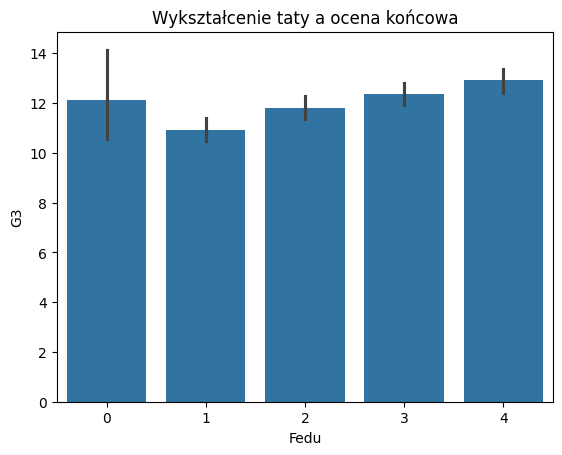

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=dane, x='Fedu', y='G3')
plt.title("Wykształcenie taty a ocena końcowa")
plt.show()

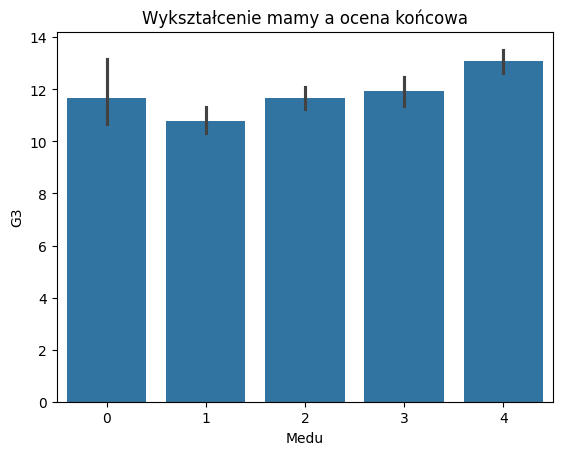

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.barplot(data=dane, x='Medu', y='G3')
plt.title("Wykształcenie mamy a ocena końcowa")
plt.show()

Po przeanalizowaniu wykresów widać, że problem ze średnią wynikał z tego, że dane dla zerowego poziomu edukacji mają bardzo dużą niepewność pomiarową.

In [ ]:
print("Liczba uczniów wg wykształcenia mamy (Medu):")
print(dane['Medu'].value_counts())

print("\nLiczba uczniów wg wykształcenia taty (Fedu):")
print(dane['Fedu'].value_counts())

Liczba uczniów wg wykształcenia mamy (Medu):
Medu
2    186
4    175
1    143
3    139
0      6
Name: count, dtype: int64

Liczba uczniów wg wykształcenia taty (Fedu):
Fedu
2    209
1    174
3    131
4    128
0      7
Name: count, dtype: int64


Tak jak wynika z poprzedniego punktu, liczba rodziców z zerową edukacją jest nieproporcjonalnie mniejsza do reszty.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Cechy ucznia (bez ocen cząstkowych G1 i G2)
cechy_z_rodzicami = ['Medu', 'Fedu', 'age', 'studytime', 'failures', 'absences', 'goout', 'Dalc', 'Walc']
cechy_bez_rodzicow = ['age', 'studytime', 'failures', 'absences', 'goout', 'Dalc', 'Walc']

cel = dane['G3'] # Cel

# 2. TEST A: Model Z wykształceniem rodziców
X1_train, X1_test, y_train, y_test = train_test_split(dane[cechy_z_rodzicami], cel, test_size=0.2, random_state=42)
model_1 = RandomForestRegressor(random_state=42)
model_1.fit(X1_train, y_train) # Trening
zgadywane_1 = model_1.predict(X1_test) #Test
blad_1 = mean_absolute_error(y_test, zgadywane_1) # Błąd statystyczny

# 3. TEST B: Model BEZ wykształcenia rodziców (zabieramy Medu i Fedu)
X2_train, X2_test, y_train, y_test = train_test_split(dane[cechy_bez_rodzicow], cel, test_size=0.2, random_state=42)
model_2 = RandomForestRegressor(random_state=42)
model_2.fit(X2_train, y_train) # Trening
zgadywane_2 = model_2.predict(X2_test) #Test
blad_2 = mean_absolute_error(y_test, zgadywane_2) # Błąd statystyczny

print("Średni błąd modelu Z wykształceniem rodziców:", round(blad_1, 3), "punktu")
print("Średni błąd modelu BEZ wykształcenia rodziców:", round(blad_2, 3), "punktu")

Średni błąd modelu Z wykształceniem rodziców: 2.136 punktu
Średni błąd modelu BEZ wykształcenia rodziców: 2.203 punktu


Tutaj widać, że model czerpie informacje z poziomu wykształcenia rodziców, ponieważ bez korzystania z nich myli się bardziej o 0,07 punktu.

Podsumowanie: wykształcenie rodziców ma mierzalny wpływ na wyniki uczniów i pomaga modelowi w trafniejszym przewidywaniu ocen.